# Beispiel aus der aktuellen Forschung: Das NCN-Molekül und der Renner-Teller-Effekt
Der **Renner–Teller-Effekt** ist eng mit dem bekannteren **Jahn–Teller-Effekt** verwandt, den man bereits aus den einführenden Chemievorlesungen kennt. Er beschreibt die Kopplung zwischen elektronischer Bewegung und Biegeschwingungen in **linearen** Molekülen. Elektronische Zustände, die bei linearer Geometrie aufgrund der räumlichen Symmetrie entartet sind, können beim Biegen des Moleküls energetisch aufspalten. Dadurch entstehen unterschiedliche Potentialflächen, die dem Schwingungsspektrum eine ungewöhnliche Struktur verleihen. 

Das dreiatomige **NCN-Radikal (Cyanonitren)** ist ein wichtiges Zwischenprodukt bei der Bildung von **Stickstoffmonoxid (NO)** in Verbrennungsprozessen, insbesondere beim sogenannten *Prompt-NO*-Mechanismus. Seine Energien und Spektren sind deshalb auch für das Verständnis dieser Reaktionswege von Bedeutung und werden auch aktuell experimentell und theoretisch untersucht. An den folgenden Potentialkurven von NCN und seinem Kation NCN$^+$ untersuchen wir, wie die Energie von der Biegung des Moleküls abhängt.


In [32]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

%matplotlib inline

In [33]:

# Die mit Matplotlib ausgelieferte Schrift funktioniert auch auf Binder.
plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "dejavuserif",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "axes.titlepad": 12,
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "legend.frameon": False,
    "lines.linewidth": 2.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "text.color": "#263238",
    "axes.labelcolor": "#263238",
})

styles = {
    "neutral": {"label": "NCN", "color": "#567A46", "linestyle": "-"},
    "cation_0": {"label": "Kurve 0", "color": "#C45E2B", "linestyle": "-"},
    "cation_1": {"label": "Kurve 1", "color": "#356D96", "linestyle": "--"},
}


def format_axes(ax, energy_label):
    ax.set_xlabel(r"Biegekoordinate $q$ (a.u.)")
    ax.set_ylabel(energy_label)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E4E8EA", linewidth=0.8)
    ax.axvline(0, color="#B8C0C5", linewidth=0.8, linestyle=":", zorder=0)
    ax.axhline(0, color="#B8C0C5", linewidth=0.8, zorder=0)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.tick_params(direction="out", length=4)


In [34]:
data_dir = Path("examples")
files = {
    "neutral": "V_bend_neutral_NCN.dat",
    "cation_0": "V_bend_cation_0_NCN.dat",
    "cation_1": "V_bend_cation_1_NCN.dat",
}

potentials = {}
for state, filename in files.items():
    data = np.loadtxt(data_dir / filename, ndmin=2)
    q, energy = data.T
    potentials[state] = {"q": q, "energy": energy}

## Elektronische Energie des NCN als Funktion der Biegekoordinate

Die Linien verbinden die eingelesenen Datenpunkte. Die beiden kationischen Kurven werden mit ihren **ursprünglichen relativen Energieoffsets** gemeinsam dargestellt. Aus den getrennten Diagrammen für NCN und NCN$^+$ lässt sich keine Ionisierungsenergie ablesen.


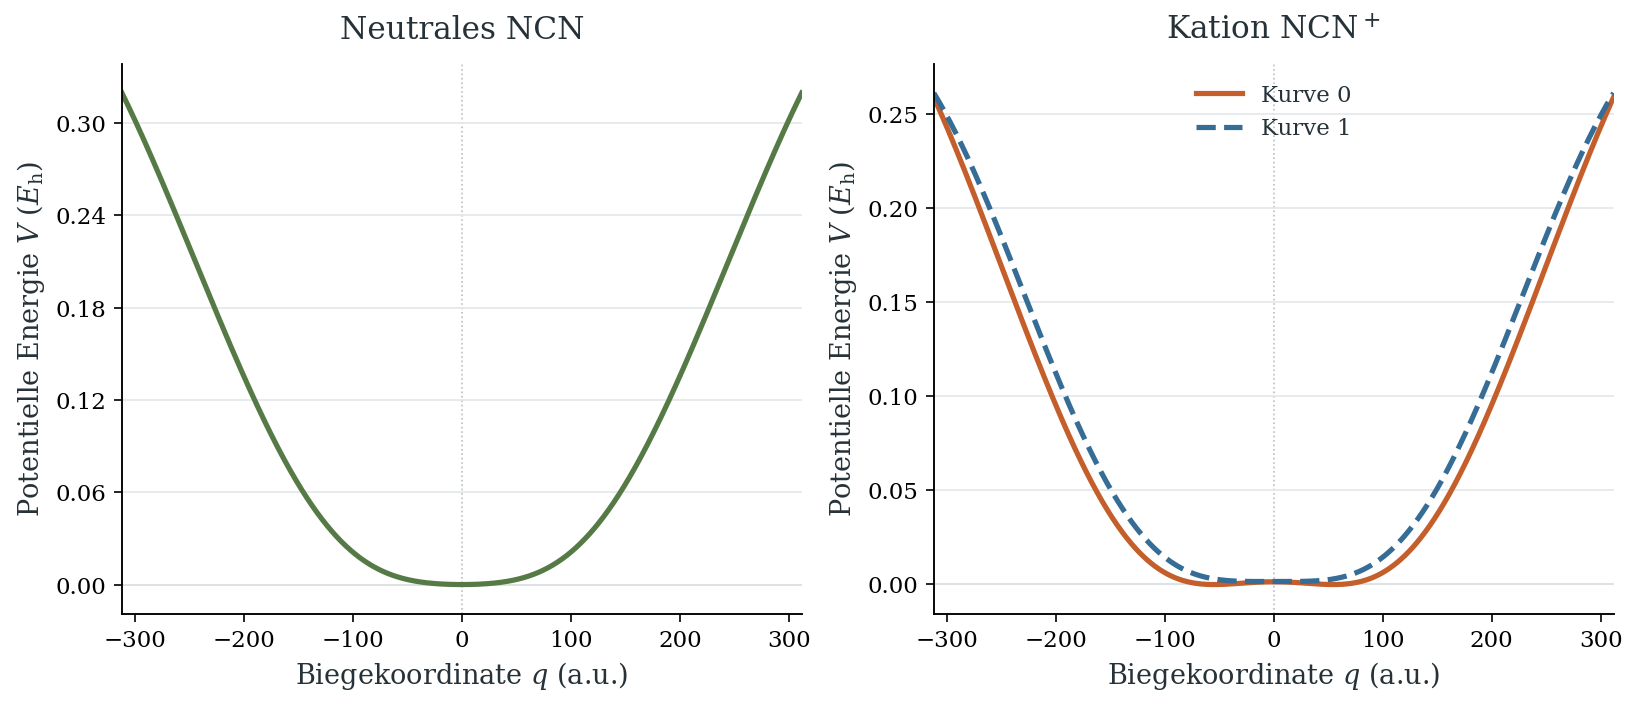

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.6), sharex=True,
                         layout="constrained")

for ax, states, title in [
    (axes[0], ("neutral",), "Neutrales NCN"),
    (axes[1], ("cation_0", "cation_1"), r"Kation NCN$^+$"),
]:
    for state in states:
        curve = potentials[state]
        ax.plot(curve["q"], curve["energy"], **styles[state])
    ax.set_title(title)
    format_axes(ax, r"Potentielle Energie $V$ ($E_\mathrm{h}$)")
    ax.margins(y=0.06)

q = potentials["neutral"]["q"]
axes[0].set_xlim(q[0], q[-1])
axes[0].set_xticks(np.arange(-300, 301, 100))
axes[1].legend(loc="upper center")
plt.show()


## Die kationischen Potentiale nahe ihren Minima



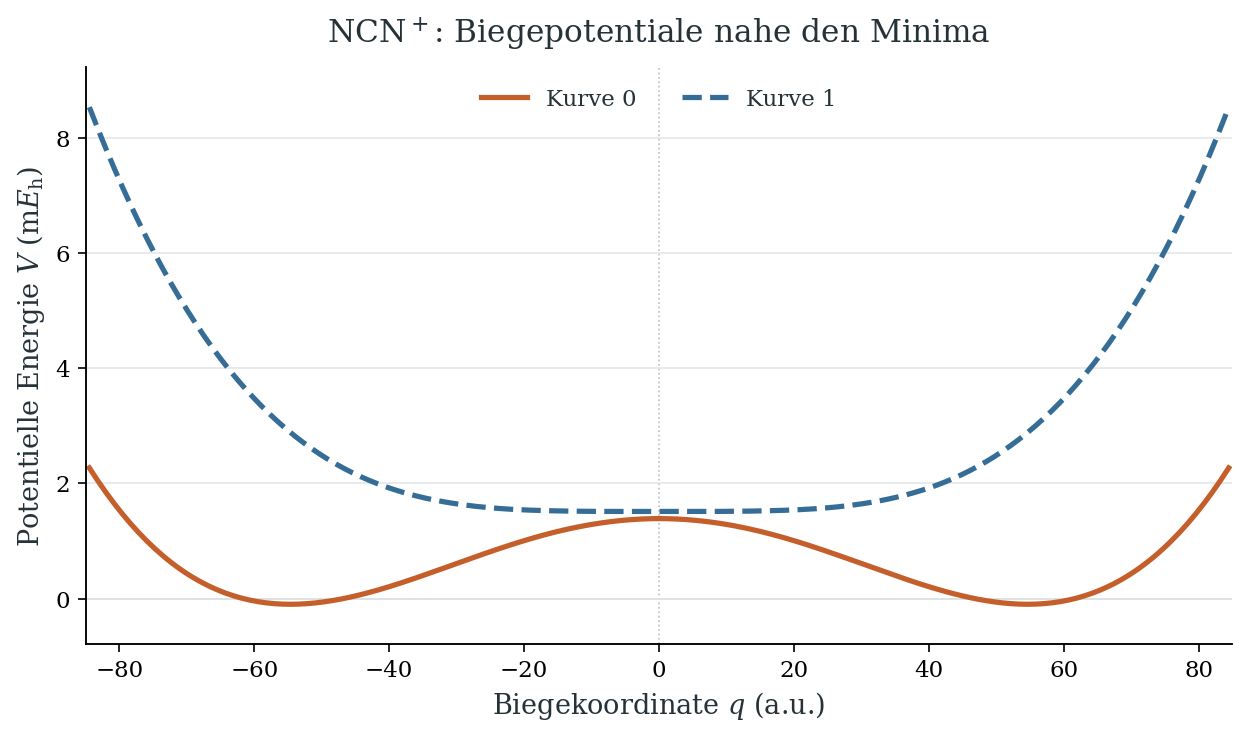

In [36]:
# Der Ausschnitt kann durch Ändern von q_zoom angepasst werden.
q_zoom = 85.0  # atomare Einheiten
fig, ax = plt.subplots(figsize=(8.2, 4.8), layout="constrained")
zoom_energies = []

for state in ("cation_0", "cation_1"):
    curve = potentials[state]
    mask = np.abs(curve["q"]) <= q_zoom
    energy_mEh = 1000.0 * curve["energy"][mask]
    zoom_energies.append(energy_mEh)
    ax.plot(curve["q"][mask], energy_mEh, **styles[state])

visible_energy = np.concatenate(zoom_energies)
padding = 0.08 * np.ptp(visible_energy)
ax.set_xlim(-q_zoom, q_zoom)
ax.set_ylim(visible_energy.min() - padding, visible_energy.max() + padding)
ax.set_xticks(np.arange(-80, 81, 20))
ax.set_title(r"NCN$^+$: Biegepotentiale nahe den Minima")
format_axes(ax, r"Potentielle Energie $V$ ($\mathrm{m}E_\mathrm{h}$)")
ax.legend(loc="upper center", ncols=2)
plt.show()


## Neutrales NCN: quadratischer oder quartischer Ansatz?

Wir vergleichen nahe dem Minimum zwei **reine Potenzansätze**:

$$
V_2(q)=a\,q^2,\qquad V_4(q)=b\,q^4.
$$

Beide Modelle besitzen genau **einen Fitparameter**. Wir bestimmen ihn durch Minimierung der Summe der quadrierten Abweichungen zu denselben, gleich gewichteten Datenpunkten im Bereich $|q|\leq85$ a.u. Der Bereich lässt sich im folgenden Code über `q_fit_max` verändern.



## Ein quartisches Modell für die zweite kationische Potentialkurve

Die zweite kationische Potentialkurve (`cation_1`) lässt sich im Bereich $|q|\leq85$ a.u. gut durch einen **quartischen Ansatz** beschreiben:

$$
\Delta V(q)=V(q)-V_\mathrm{ref}\approx bq^4.
$$

Die Referenzenergie $V_\mathrm{ref}$ bei $q=0$ schätzen wir aus den beiden benachbarten Datenpunkten ab. `curve_fit` bestimmt $b$ so, dass die Summe der quadrierten Abweichungen zwischen Modell und Daten möglichst klein wird.


In [37]:
from scipy.optimize import curve_fit

# Zweite kationische Kurve auswählen und Energie bei q = 0 abziehen.
q = potentials["cation_1"]["q"]
V = potentials["cation_1"]["energy"]
V_ref = np.interp(0, q, V)
mask = np.abs(q) <= 85
q = q[mask]
V = V[mask] - V_ref

# Quartisches Modell an die Daten anpassen.
def quartic(q, b):
    return b * q**4

parameters, _ = curve_fit(quartic, q, V)
b = parameters[0]
print(f"b = {b:.3e} (a.u.)")


b = 1.425e-10 (a.u.)


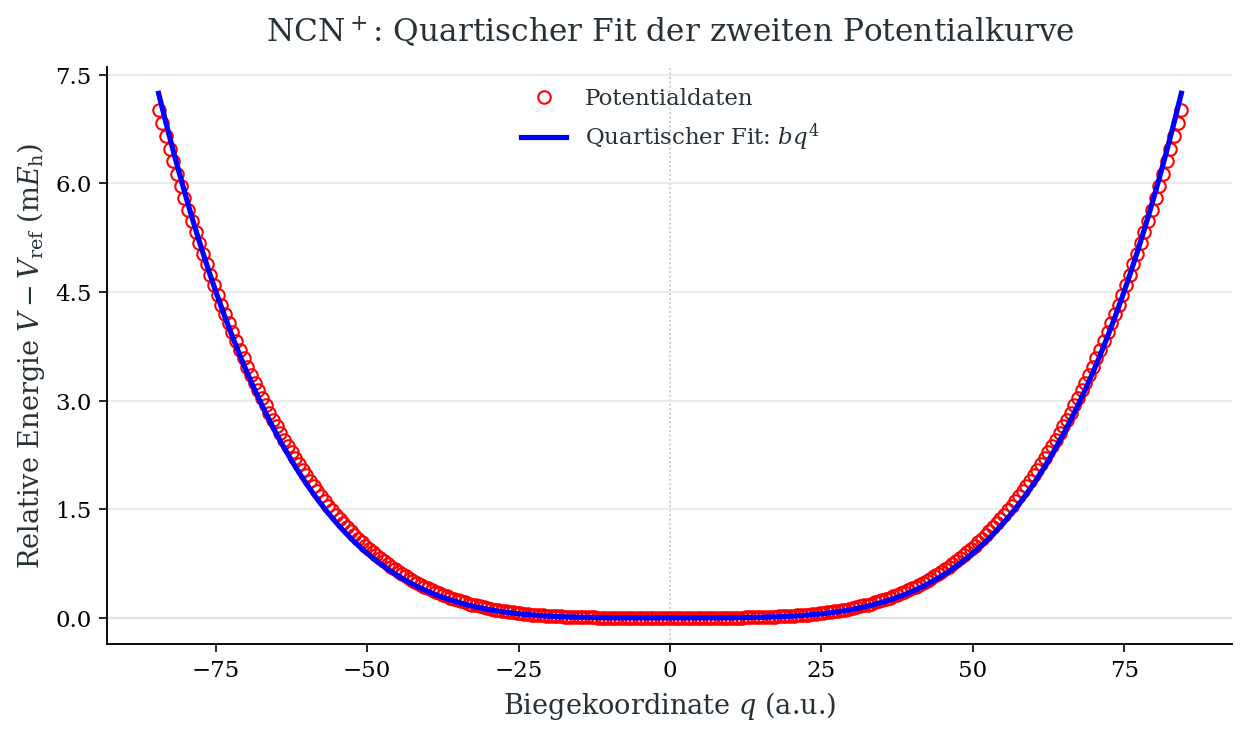

In [38]:
fig, ax = plt.subplots(figsize=(8.2, 4.8), layout="constrained")
ax.plot(q, 1000 * V, "o", 
        markerfacecolor="none", 
        markeredgecolor="red",
        label="Potentialdaten")
ax.plot(q, 1000 * quartic(q, b), "-", color= "blue",
        label=r"Quartischer Fit: $bq^4$")

format_axes(ax, r"Relative Energie $V-V_\mathrm{ref}$ ($\mathrm{m}E_\mathrm{h}$)")
ax.set_title(r"NCN$^+$: Quartischer Fit der zweiten Potentialkurve")
ax.legend(loc="upper center")
plt.show()


## Schwingungszustände mit dem Ritz–Galerkin-Verfahren

Für die massengewichtete Biegekoordinate verwenden wir in atomaren Einheiten

$$
\hat H=-\frac12\frac{\mathrm d^2}{\mathrm dq^2}+bq^4.
$$

Wie im Kapitel zum Variationsprinzip entwickeln wir die Wellenfunktionen in Gaußfunktionen mit Polynomfaktoren:

$$
\psi_k(q)=\sum_{n=0}^{N-1}c_n^{(k)}\varphi_n(q),\qquad
\varphi_n(q)=q^n e^{-\beta q^2},\qquad
\beta=\frac{(6b)^{1/3}}{2}.
$$

Die Gaußbreite stammt aus der dortigen Ein-Gauß-Optimierung und bleibt für alle Basisgrößen fest. Für die **fünf niedrigsten Zustände** brauchen wir sowohl gerade als auch ungerade Potenzen.

Die analytischen Gaußintegrale liefern die Matrixelemente:

$$
I_l=\int_{-\infty}^{\infty}q^l e^{-2\beta q^2}\,\mathrm dq
=\begin{cases}
\displaystyle\frac{\Gamma((l+1)/2)}{(2\beta)^{(l+1)/2}},&l\text{ gerade},\\
0,&l\text{ ungerade},
\end{cases}
$$

$$
S_{ij}=I_{i+j},\qquad
T_{ij}=\frac{ij}{2}I_{i+j-2}-\beta(i+j)I_{i+j}+2\beta^2 I_{i+j+2},\qquad
H_{ij}=T_{ij}+bI_{i+j+4}.
$$

Der erste Term in $T_{ij}$ entfällt für $i=0$ oder $j=0$. Wir normieren die Basisfunktionen einzeln, damit die Matrixeinträge numerisch gut handhabbar bleiben.

Wie zuvor betrachten wir ein eindimensionales quartisches Modell, das über den Fitbereich hinaus fortgesetzt wird. Die Energien beziehen sich auf $V_\mathrm{ref}$.


In [39]:
from scipy.special import gamma
from scipy.linalg import eigh

beta = (6 * b)**(1/3) / 2
Nmax = 10

def I(l):
    if l % 2:  # Ungerade Integrale verschwinden.
        return 0.0
    return gamma((l + 1) / 2) / (2 * beta)**((l + 1) / 2)

S = np.zeros((Nmax, Nmax))
H = np.zeros_like(S)
for i in range(Nmax):
    for j in range(Nmax):
        l = i + j
        S[i, j] = I(l)
        T = -beta * l * I(l) + 2 * beta**2 * I(l + 2)
        if i > 0 and j > 0:
            T += i * j * I(l - 2) / 2
        H[i, j] = T + b * I(l + 4)

# Jede Basisfunktion durch ihre Norm teilen.
norm = np.sqrt(np.diag(S))
H /= np.outer(norm, norm)
S /= np.outer(norm, norm)


Für $N=5,\ldots,10$ lösen wir $\mathbf H\mathbf c=E\mathbf S\mathbf c$ und speichern die fünf niedrigsten Energien. Mit wachsender Basis nähern sie sich den exakten Energien des quartischen Modells **von oben**. Die Plateaus entstehen, weil eine neue gerade Basisfunktion nur gerade Zustände verbessert, eine ungerade nur ungerade.


In [40]:
sizes = np.arange(5, Nmax + 1)
E_N = []
for N in sizes:
    energies, coefficients = eigh(H[:N, :N], S[:N, :N])
    E_N.append(energies[:5])
E_N = np.array(E_N)
energies = E_N[-1]

print(f"N = {Nmax}: Energien in mHartree")
for k, energy in enumerate(energies):
    print(f"E_{k} = {1000 * energy:.6f}")


N = 10: Energien in mHartree
E_0 = 0.348919
E_1 = 1.250236
E_2 = 2.456643
E_3 = 3.840620
E_4 = 5.369598


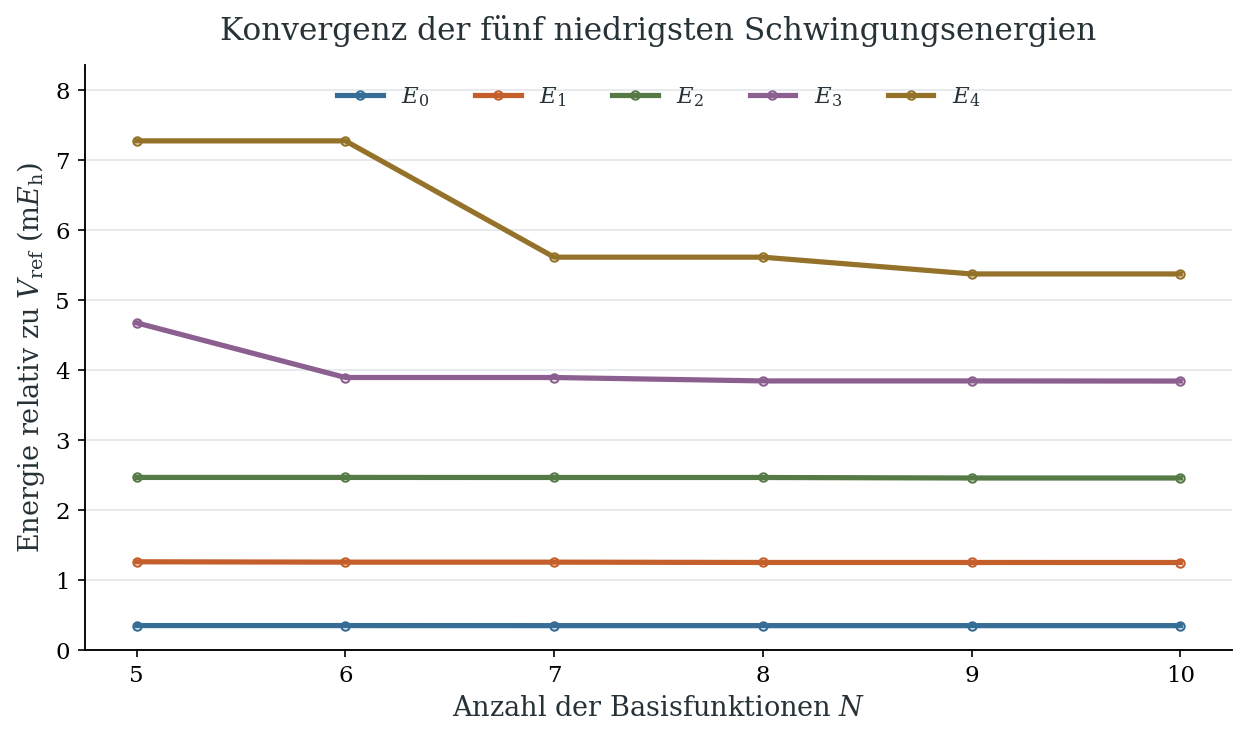

In [41]:
fig, ax = plt.subplots(figsize=(8.2, 4.8), layout="constrained")
colors = ["#356D96", "#C45E2B", "#567A46", "#8B5F8F", "#947229"]
for k in range(5):
    ax.plot(sizes, 1000 * E_N[:, k], "o-", color=colors[k],
            markerfacecolor="none", markersize=4, label=fr"$E_{k}$")

ax.set_xlabel(r"Anzahl der Basisfunktionen $N$")
ax.set_ylabel(r"Energie relativ zu $V_\mathrm{ref}$ ($\mathrm{m}E_\mathrm{h}$)")
ax.set_xticks(sizes)
ax.set_ylim(0, 1.15 * 1000 * E_N.max())
ax.set_title("Konvergenz der fünf niedrigsten Schwingungsenergien")
ax.grid(axis="y", color="#E4E8EA", linewidth=0.8)
ax.legend(ncols=5, loc="upper center")
plt.show()


Aus den Eigenvektoren erhalten wir die fünf Wellenfunktionen für die größte Basis. Sie sind normiert und werden zur Darstellung mit einem gemeinsamen Faktor skaliert und auf ihre jeweilige Energie verschoben.


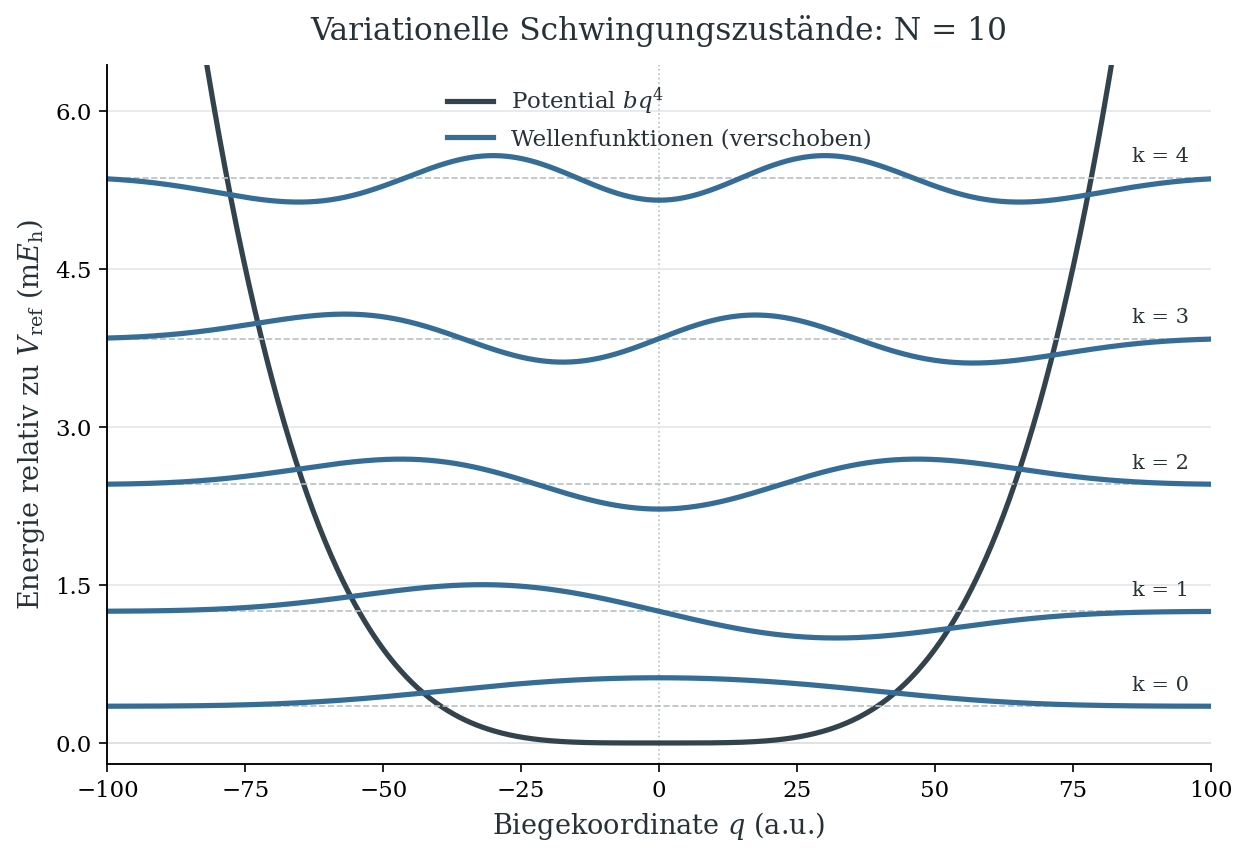

In [42]:
q_grid = np.linspace(-160, 160, 1201)
basis = np.array([q_grid**n * np.exp(-beta * q_grid**2) / norm[n]
                  for n in range(Nmax)])
psi = basis.T @ coefficients[:, :5]

fig, ax = plt.subplots(figsize=(8.2, 5.6), layout="constrained")
ax.plot(q_grid, 1000 * quartic(q_grid, b), color="#33434D", label=r"Potential $bq^4$")
scale = 0.3 * (energies[1] - energies[0]) / np.max(np.abs(psi))
for k, energy in enumerate(energies):
    ax.axhline(1000 * energy, color="#B8C0C5", linestyle="--", linewidth=0.8)
    ax.plot(q_grid, 1000 * (energy + scale * psi[:, k]), color="#356D96",
            label="Wellenfunktionen (verschoben)" if k == 0 else None)
    ax.text(96, 1000 * energy + 0.15, f"k = {k}", ha="right", fontsize=10)

format_axes(ax, r"Energie relativ zu $V_\mathrm{ref}$ ($\mathrm{m}E_\mathrm{h}$)")
ax.set_xlim(-100, 100)
ax.set_ylim(-0.2, 1.2 * 1000 * energies[-1])
ax.set_title(f"Variationelle Schwingungszustände: N = {Nmax}")
ax.legend(loc="upper center")
plt.show()


## Harmonischer und quartischer Oszillator im Vergleich

Beim **harmonischen Oszillator** sind die Energieniveaus gleichmäßig angeordnet:

$$
E_n=\hbar\omega\left(n+\frac12\right),\qquad E_{n+1}-E_n=\hbar\omega.
$$

Im **reinen quartischen Potential** $V(q)=bq^4$ wachsen dagegen die Abstände zwischen benachbarten Niveaus mit der Anregung. Semiklassisch gilt für große Quantenzahlen

$$
E_n\propto\left(n+\frac12\right)^{4/3},
$$

also ein stärkerer Anstieg im Vergleich zu dem linearen Anstieg der Energieniveaus beim harmonischen Oszillator. 

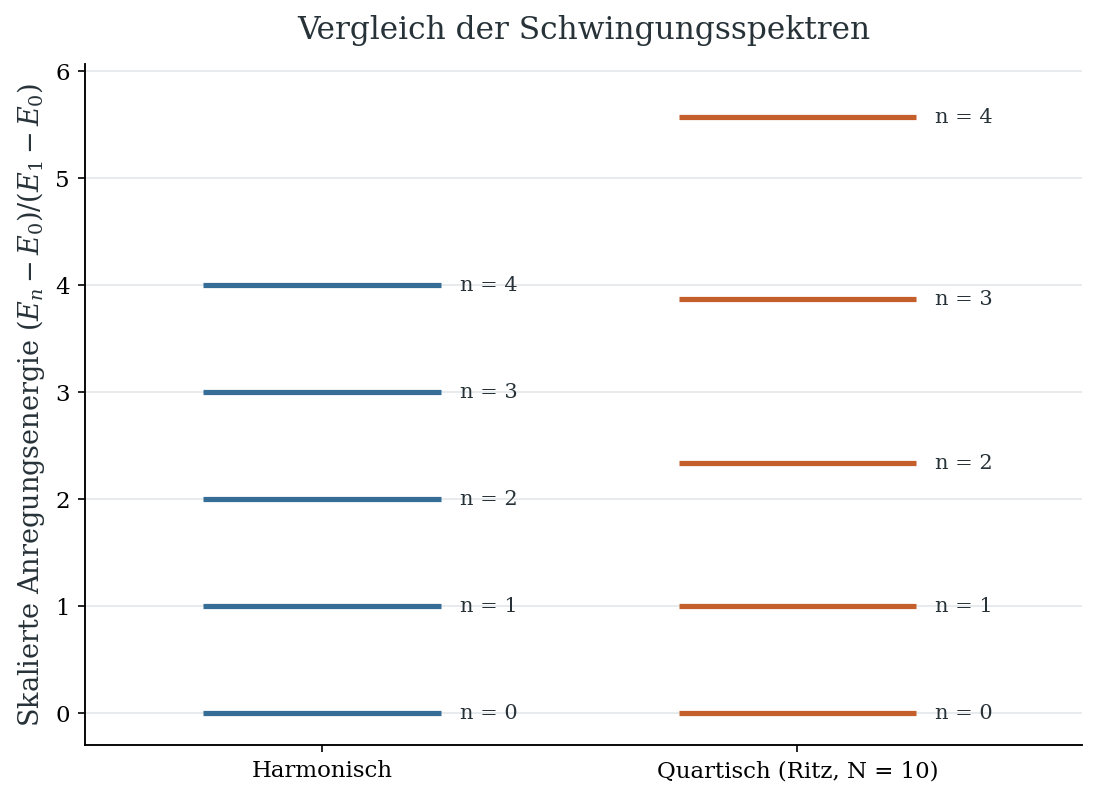

In [43]:
n = np.arange(len(energies))
quartic_levels = (energies - energies[0]) / (energies[1] - energies[0])

fig, ax = plt.subplots(figsize=(7.2, 5.2), layout="constrained")
for x, levels, color in [(0, n, "#356D96"), (1, quartic_levels, "#C45E2B")]:
    ax.hlines(levels, x - 0.25, x + 0.25, color=color, linewidth=2.5)
    for k, level in enumerate(levels):
        ax.text(x + 0.29, level, f"n = {k}", va="center", fontsize=10)

ax.set_xticks([0, 1], ["Harmonisch", f"Quartisch (Ritz, N = {Nmax})"])
ax.set_xlim(-0.5, 1.6)
ax.set_ylim(-0.3, quartic_levels[-1] + 0.5)
ax.set_ylabel(r"Skalierte Anregungsenergie $(E_n-E_0)/(E_1-E_0)$")
ax.set_title("Vergleich der Schwingungsspektren")
ax.grid(axis="y", color="#E4E8EA", linewidth=0.8)
ax.set_axisbelow(True)
plt.show()
